# 04.13 · Caminatas aleatorias, difusión y finanzas
**Complemento al temario oficial.** El núcleo gaussiano de 04.01 aparece como límite de una caminata y como propagador al cambiar variables en la ecuación de Black–Scholes.

### Proposición 04.13.1 · Escalamiento difusivo

**Complemento.** Al duplicar el número de pasos en el mismo intervalo de tiempo, ¿qué longitud debe tener cada salto para ver la misma nube? Las varianzas de saltos centrados e independientes se suman. Para conservar $nh^2$ hay que dividir $h$ por $\sqrt2$. Conservar $nh$, como en un movimiento siempre hacia adelante, llevaría a una nube de varianza decreciente. Éste es el contenido probabilístico del escalamiento $h^2/\tau$ constante.

En cada intervalo $\tau$ una partícula salta $\pm h$ con probabilidades iguales. Su masa obedece $p_j^{k+1}=(p_{j-1}^k+p_{j+1}^k)/2$. Restar $p_j^k$ y dividir por $\tau$ produce un laplaciano discreto con $D=h^2/(2\tau)$. La varianza después de $k$ pasos es $kh^2=2Dt$. Taylor da la ecuación límite $p_t=Dp_{xx}$ para perfiles suaves. Para una masa inicial en el origen, el teorema central del límite identifica la ley gaussiana a tiempo fijo.

### Ejemplo 04.13.2 · Paridad de la malla
Con $t=1$, $h=1/\sqrt n$ y $\tau=1/n$ se obtiene $D=1/2$. Sólo son accesibles $x=(2j-n)h$. Para comparar masas con una **densidad** hay que dividir por la distancia $2h$. La curva continua tiene varianza uno.


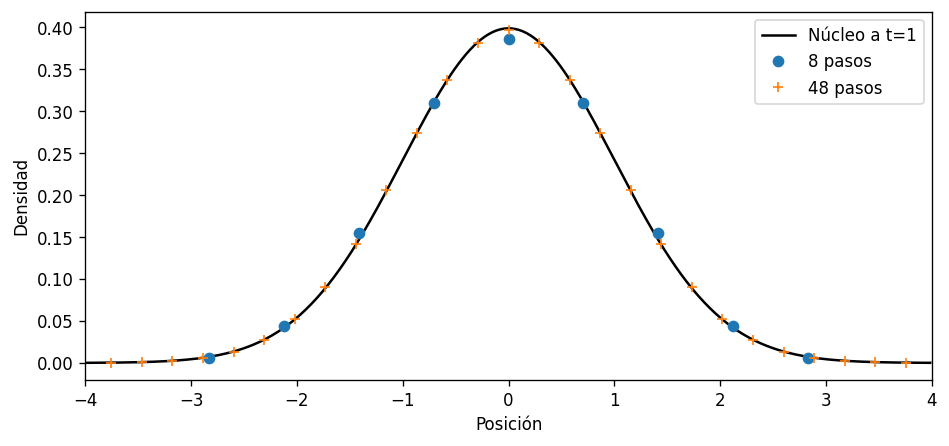

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-4, 4, 450)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(x, np.exp(-x*x/2)/np.sqrt(2*np.pi), color="black", label="Núcleo a t=1")
for n, marker in [(8, "o"), (48, "+")]:
    h = 1/np.sqrt(n)
    j = np.arange(n+1)
    masas = np.array([math.comb(n, int(k))/2**n for k in j])
    assert np.isclose(masas.sum(), 1)
    ax.plot((2*j-n)*h, masas/(2*h), marker, label=f"{n} pasos")
ax.set(xlim=(-4,4), xlabel="Posición", ylabel="Densidad")
ax.legend()
fig.tight_layout()
plt.show()

### Proposición 04.13.3 · Reducción de Black–Scholes a calor

**Por qué usar el logaritmo y dar vuelta al reloj.** El ruido del modelo escala con el precio $S$. Un cambio proporcional $S\mapsto S e^h$ se convierte en un desplazamiento fijo $h$ en $\log S$. El dato conocido es el pago al vencimiento; $\tau=T-t$ mide cuánto tiempo de difusión hay entre ese pago y el precio que se calcula. Para un pago con esquina, como $(S-K)_+$, la convolución redondea la esquina cuando $\tau>0$ y la recupera al acercarse el vencimiento.

Para volatilidad $\sigma>0$, tasa constante $r$ y pago terminal $H(S)$, el modelo sin dividendos satisface $V_t+\tfrac12\sigma^2 S^2V_{SS}+rSV_S-rV=0$ en $S>0$. Escribe $\tau=T-t$, $x=\log(S/K)$ con $K>0$, y $W(x,\tau)=e^{r\tau}V(Ke^x,T-\tau)$. Como $S^2V_{SS}=V_{xx}-V_x$ al expresar $V$ en coordenada logarítmica, se obtiene $W_\tau=DW_{xx}+bW_x$, donde $D=\sigma^2/2$, $b=r-D$. Tomar $U(y,\tau)=W(y-b\tau,\tau)$ elimina el transporte.

Para un pago continuo de crecimiento a lo sumo lineal en $S$, la convolución converge y recupera el dato al tender $\tau$ a cero. Con $G_D(z,\tau)=e^{-z^2/(4D\tau)}/\sqrt{4\pi D\tau}$,
$$V(S,T-\tau)=e^{-r\tau}\int_{\mathbb R}G_D(x+b\tau-z,\tau)\,H(Ke^z)\,dz.$$
Para $H=1$ resulta $e^{-r\tau}$. Para $H(S)=S$ el momento exponencial del núcleo da exactamente $S$, lo que verifica el signo de la traslación.

### Ejercicios de práctica
#### Ejercicio 04.13.1

Calcula la función característica de la caminata reescalada y demuestra su convergencia a $e^{-\xi^2/2}$ a tiempo uno.

#### Ejercicio 04.13.2

Para $H(S)=(S-K)_+$, identifica el intervalo de integración efectivo. Justifica que el precio recupera el pago al vencimiento usando el núcleo del calor.
